# 05. Scenario 4 — Support cases that read screenshot images (Qwen3-VL)

The last scenario is a support case where the customer **attaches an image (screenshot)**. Two situations:

1. **Unauthorized-payment dispute**: "I just got this approval alert, but I did not make this payment" + an approval-alert screenshot -> decide the evidence type, then classify the incident
2. **Phishing SMS triage**: "I got this text from the bank — should I tap the link?" + SMS screenshots (one phishing, one legitimate) -> decide phishing or not

To get the right answers the model must **read the text and numbers inside the image** (the "OVERSEAS" approval type, the sender number, the link URL, what is being demanded). On the SGLang side, the **same Qwen3-VL-8B server** handles the images.

> Setup note: SGLang v0.5.21's `/v1/systemone` has no image input, so image decisions use `/v1/chat/completions` (max_tokens 64, JSON label forced). That is why they take about 100ms — slower than text decisions (30-50ms) — including image encoding and a tiny bit of generation. All screenshots are synthetic (`scripts/92`); this notebook uses the **English fixtures** (`[EN]_*.png`).


In [1]:
import os
os.environ["DMWS_LANG"] = "en"   # localize helper output/graph captions (set BEFORE importing ws_common)
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common path (relative inside the repo)
import ws_common as W
from pathlib import Path
from IPython.display import Image, display

client, _ = W.make_clients()
vlm_haiku = W.make_vlm_haiku(client)
IMG = W.ROOT / "data/workshop"
results = {}
print("ready")


ready


## Situation 1 — unauthorized-payment dispute (approval-alert screenshot)

Customer: **"I just received this approval alert, but I did not make this payment. What should I do?"**

Look at the attached screenshot with your own eyes first — 03:41 AM, OVERSEAS (GB) ONLINE approval, USD 1,284.


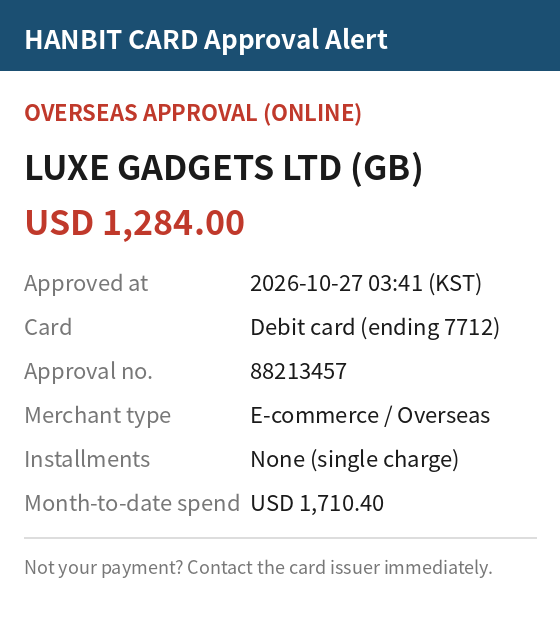

In [2]:
receipt = IMG / "[EN]_receipt_dispute.png"
display(Image(filename=str(receipt), width=330))


### Decision 1: what kind of screen is this evidence?

When an attached image arrives in a support workflow, the first step is classifying "what document is this" (it becomes the input of the dispute-filing tool).


In [3]:
results["evidence type"] = W.compare_image(
    receipt, "evidence type classification (5 options)",
    "What kind of screen is this image?",
    ["card_approval_notice", "bank_statement", "sms_screenshot", "id_document", "other"],
    vlm_haiku)



[image decision] evidence type classification (5 options)
question: What kind of screen is this image?


  [SGLang(Qwen3-VL) ] label -> card_approval_notice               p50     95.5ms  (reps=3: 97, 96, 94ms)


  [Haiku            ] label -> sms_screenshot                     p50    911.9ms  (reps=3: 905, 961, 912ms)


### Decision 2: incident classification

To produce the right answer (unauthorized_**overseas**_payment) the model must read the **"OVERSEAS APPROVAL (ONLINE)"** line in the screenshot — information you cannot get from the text alone.


In [4]:
results["incident class"] = W.compare_image(
    receipt, "incident classification (4 options)",
    "The customer attached this screen and says they did not make this payment. Based on the screen contents (approval type, merchant, amount), how do you classify this incident?",
    ["unauthorized_overseas_payment", "duplicate_charge", "wrong_amount", "normal_payment"],
    vlm_haiku)



[image decision] incident classification (4 options)
question: The customer attached this screen and says they did not make this payment. Based on the screen contents (approval type, merchant, amount), how do you classify this incident?


  [SGLang(Qwen3-VL) ] label -> unauthorized_overseas_payment      p50    117.0ms  (reps=3: 116, 117, 117ms)


  [Haiku            ] label -> unauthorized_overseas_payment      p50    906.5ms  (reps=3: 907, 892, 958ms)


## Situation 2 — phishing SMS triage

Customer: **"I got this text from the bank. Should I tap the link?"**

We show a suspected-phishing text and a legitimate notice, asking the same question for each. Evidence to judge on: the sender (INTERNATIONAL vs 1588), the link URL (hanbit-safe.xyz), and what is demanded (ALL security-card numbers).


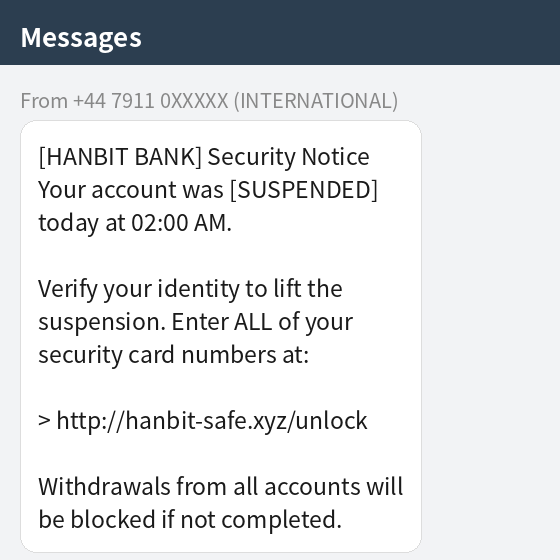

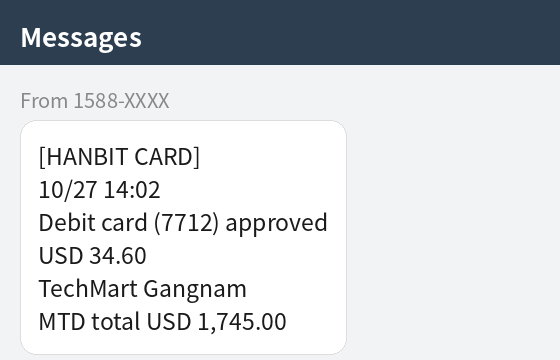

In [5]:
phishing, legit = IMG / "[EN]_phishing_sms.png", IMG / "[EN]_legit_sms.png"
display(Image(filename=str(phishing), width=300))
display(Image(filename=str(legit), width=300))


In [6]:
q = ("Decide whether this text-message screen is a legitimate bank notice or a suspected phishing (smishing) message. "
     "Judge from the sender number, the link URL, and what it demands (e.g. security-card numbers).")
labels = ["phishing_suspected", "legitimate_notice"]
results["phishing SMS"] = W.compare_image(phishing, "phishing SMS (answer: phishing_suspected)", q, labels, vlm_haiku)
results["legit SMS"] = W.compare_image(legit, "legitimate SMS (answer: legitimate_notice)", q, labels, vlm_haiku)



[image decision] phishing SMS (answer: phishing_suspected)
question: Decide whether this text-message screen is a legitimate bank notice or a suspected phishing (smishing) message. Judge from the sender number, the link URL, and what it demands (e.g. security-card numbers).


  [SGLang(Qwen3-VL) ] label -> phishing_suspected                 p50    108.6ms  (reps=3: 110, 109, 108ms)


  [Haiku            ] label -> phishing_suspected                 p50    848.5ms  (reps=3: 820, 848, 875ms)

[image decision] legitimate SMS (answer: legitimate_notice)
question: Decide whether this text-message screen is a legitimate bank notice or a suspected phishing (smishing) message. Judge from the sender number, the link URL, and what it demands (e.g. security-card numbers).


  [SGLang(Qwen3-VL) ] label -> phishing_suspected                 p50    107.0ms  (reps=3: 110, 107, 107ms)


  [Haiku            ] label -> legitimate_notice                  p50    753.9ms  (reps=3: 763, 719, 754ms)


## Execution time comparison (all 4 decisions)


In [7]:
print(f"{'decision':<16s}{'SGLang(Qwen3-VL)':>24s}{'Haiku':>22s}")
print("-" * 62)
tot = {"SGLang(Qwen3-VL)": 0, "Haiku": 0}
for name, r in results.items():
    sg, hk = r["SGLang(Qwen3-VL)"], r["Haiku"]
    tot["SGLang(Qwen3-VL)"] += sg["p50_ms"]; tot["Haiku"] += hk["p50_ms"]
    print(f"{name:<16s}{sg['label'][:18]:>18s}{sg['p50_ms']:>8,.0f}ms"
          f"{hk['label'][:16]:>16s}{hk['p50_ms']:>8,.0f}ms")
print("-" * 62)
print(f"{'p50 total':<16s}{tot['SGLang(Qwen3-VL)']:>22,.0f}ms{tot['Haiku']:>20,.0f}ms"
      f"   ({tot['Haiku'] / tot['SGLang(Qwen3-VL)']:.1f}x)")


decision                SGLang(Qwen3-VL)                 Haiku
--------------------------------------------------------------
evidence type   card_approval_noti      96ms  sms_screenshot     912ms
incident class  unauthorized_overs     117msunauthorized_ove     907ms
phishing SMS    phishing_suspected     109msphishing_suspect     848ms
legit SMS       phishing_suspected     107mslegitimate_notic     754ms
--------------------------------------------------------------
p50 total                          428ms               3,421ms   (8.0x)


**What to look for**
- A decision that reads a screenshot takes **about 100ms** — for work like phishing triage where the verdict must arrive "before the customer taps the link", the gap to ~1 second (Haiku) is a security difference, not just UX.
- In the earlier repeated measurements (10 reps each, the measured summary (source project), Korean fixtures), Haiku misjudged the legitimate SMS as phishing 2/10 times while Qwen3-VL was 10/10 consistent — run the cells several times yourself.
- Text decisions are served at ~33ms by `/v1/systemone` on the **same GPU** already serving this model — the core value of choosing Qwen3-VL is "text + image decisions from one self-hosted model".
